# Lab Assignment 04 — Image Denoising Using Autoencoders

This notebook implements the complete experiment described in the assignment PDF:

1. Load and inspect MNIST.
2. Audit the ten digit classes for imbalance.
3. Normalize and split the data without touching the final test set.
4. Create Gaussian-corrupted inputs at noise levels 0.1–0.5.
5. Build and train five required autoencoders: undercomplete, sparse, denoising, convolutional, and contractive.
6. Evaluate using MSE, MAE, PSNR, and SSIM.
7. Compare architectures, training cost, and reconstructions.
8. Study noise-level and latent-dimension effects.
9. Save the best model and generate a Streamlit deployment app.

**Important:** MNIST is an image-reconstruction task. SMOTE is designed for tabular feature vectors and is not a sound way to generate image/target pairs here. This notebook measures digit-class counts and uses per-image class-balanced loss weights so each digit contributes equally to training. Gaussian noise is used as realistic corruption augmentation. The test set remains unweighted and untouched by model fitting.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Environment and experiment configuration

In [ ]:
# If running in Google Colab, uncomment the next line if packages are missing.
# %pip install -q tensorflow matplotlib pandas scikit-learn scikit-image pillow streamlit

import os
os.environ["PYTHONHASHSEED"] = "42"

import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Reproducibility can reduce performance slightly on some GPU configurations.
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# Avoid TensorFlow reserving all GPU memory at startup.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())

OUTPUT_DIR = Path("outputs")
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"
RESULT_DIR = OUTPUT_DIR / "results"
for folder in (MODEL_DIR, PLOT_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

IMAGE_H = 28
IMAGE_W = 28
IMAGE_SIZE = IMAGE_H * IMAGE_W
NUM_CLASSES = 10
TRAIN_NOISE_SIGMA = 0.30
NOISE_LEVELS = [0.1, 0.2, 0.3, 0.4, 0.5]
LATENT_DIMS = [8, 16, 32, 64, 128]
BATCH_SIZE = 256
EPOCHS = 15
LATENT_EPOCHS = 10
LEARNING_RATE = 1e-3
VALIDATION_SIZE = 0.10

print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
print("Output directory:", OUTPUT_DIR.resolve())

TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPU available: False
Output directory: /content/outputs


## 1. Load MNIST and inspect the dataset

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Image type: uint8
Pixel range before normalization: 0 to 255


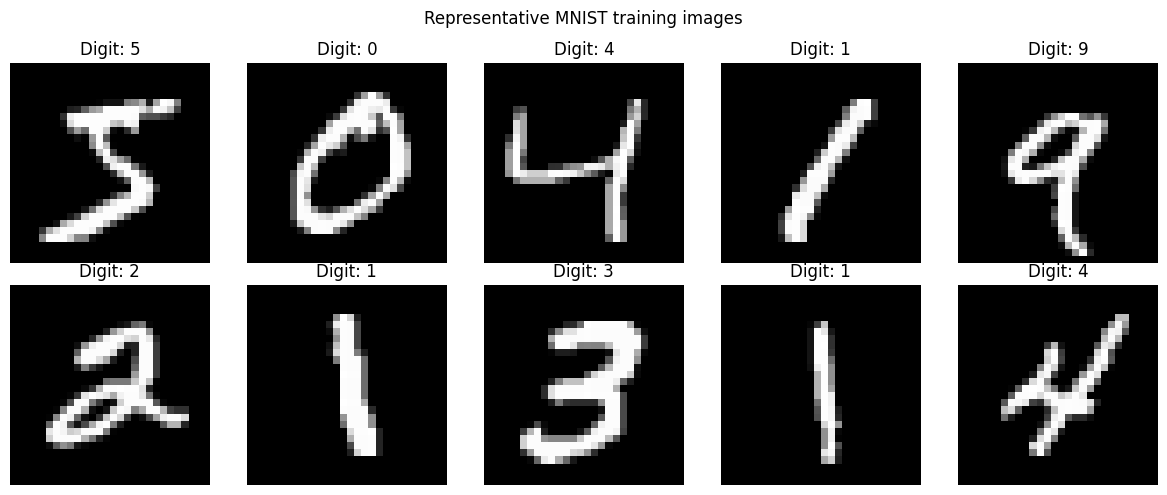

In [ ]:
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train_raw.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test_raw.shape)
print("Test labels:", y_test.shape)
print("Image type:", x_train_raw.dtype)
print("Pixel range before normalization:", int(x_train_raw.min()), "to", int(x_train_raw.max()))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, image, label in zip(axes.flat, x_train_raw[:10], y_train[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit: {label}")
    ax.axis("off")
plt.suptitle("Representative MNIST training images")
plt.tight_layout()
plt.show()

## 2. Exploratory data analysis and class-balance check

The labels are used only to audit class balance and calculate sample weights. The autoencoders still learn image-to-image reconstruction, not digit classification. The code reports exact counts and the majority/minority ratio for both official splits.

Training split: 60,000 images
Majority/minority ratio: 1.244
Exactly balanced: False
Interpretation: approximately balanced


,digit,count,percentage
0,0,5923,9.871667
1,1,6742,11.236667
2,2,5958,9.930000
3,3,6131,10.218333
4,4,5842,9.736667
5,5,5421,9.035000
6,6,5918,9.863333
7,7,6265,10.441667
8,8,5851,9.751667
9,9,5949,9.915000


Test split: 10,000 images
Majority/minority ratio: 1.272
Exactly balanced: False
Interpretation: class imbalance is present


,digit,count,percentage
0,0,980,9.80
1,1,1135,11.35
2,2,1032,10.32
3,3,1010,10.10
4,4,982,9.82
5,5,892,8.92
6,6,958,9.58
7,7,1028,10.28
8,8,974,9.74
9,9,1009,10.09


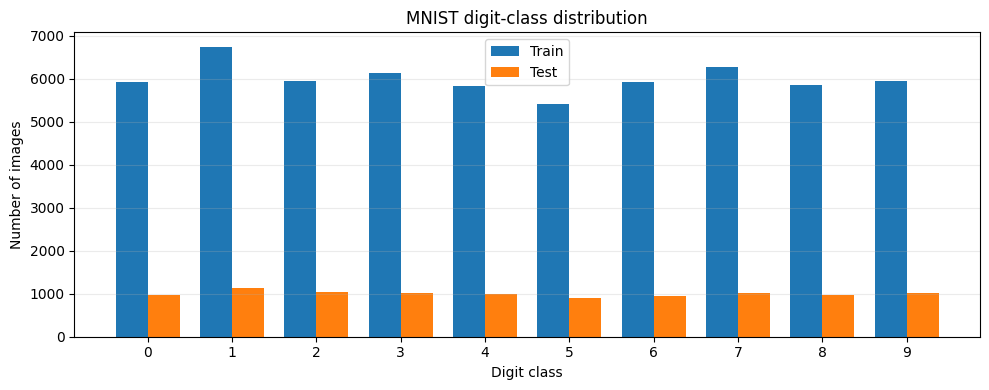

Class weights (digit 0 to 9): [1.013  0.8899 1.007  0.9786 1.027  1.1068 1.0139 0.9577 1.0255 1.0086]
Weights are used only during training/validation; test metrics use the natural test distribution.


In [ ]:
def class_distribution(labels, split_name):
    counts = np.bincount(labels, minlength=NUM_CLASSES)
    total = int(counts.sum())
    table = pd.DataFrame({
        "digit": np.arange(NUM_CLASSES),
        "count": counts,
        "percentage": counts / total * 100,
    })
    ratio = float(counts.max() / counts.min())
    print(f"{split_name}: {total:,} images")
    print(f"Majority/minority ratio: {ratio:.3f}")
    print("Exactly balanced:", bool(np.all(counts == counts[0])))
    print("Interpretation:", "approximately balanced" if ratio < 1.25 else "class imbalance is present")
    display(table)
    return counts, ratio, table

train_counts, train_imbalance_ratio, train_dist = class_distribution(y_train, "Training split")
test_counts, test_imbalance_ratio, test_dist = class_distribution(y_test, "Test split")

train_dist.to_csv(RESULT_DIR / "train_class_distribution.csv", index=False)
test_dist.to_csv(RESULT_DIR / "test_class_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.38
x = np.arange(NUM_CLASSES)
ax.bar(x - width/2, train_counts, width, label="Train")
ax.bar(x + width/2, test_counts, width, label="Test")
ax.set_xticks(x)
ax.set_xlabel("Digit class")
ax.set_ylabel("Number of images")
ax.set_title("MNIST digit-class distribution")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PLOT_DIR / "class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

# Since this is a reconstruction task, avoid SMOTE or interpolating flattened pixels.
# Inverse-frequency sample weights balance the contribution of each digit class.
class_weights = len(y_train) / (NUM_CLASSES * np.maximum(train_counts, 1))
class_weights = class_weights / np.mean(class_weights[y_train])
print("Class weights (digit 0 to 9):", np.round(class_weights, 4))
print("Weights are used only during training/validation; test metrics use the natural test distribution.")

## 3. Preprocess, split, and generate Gaussian-corrupted images

Train clean/noisy: (54000, 28, 28) (54000, 28, 28)
Validation clean/noisy: (6000, 28, 28) (6000, 28, 28)
Test clean/noisy: (10000, 28, 28) (10000, 28, 28)
Normalized pixel range: 0.0 to 1.0


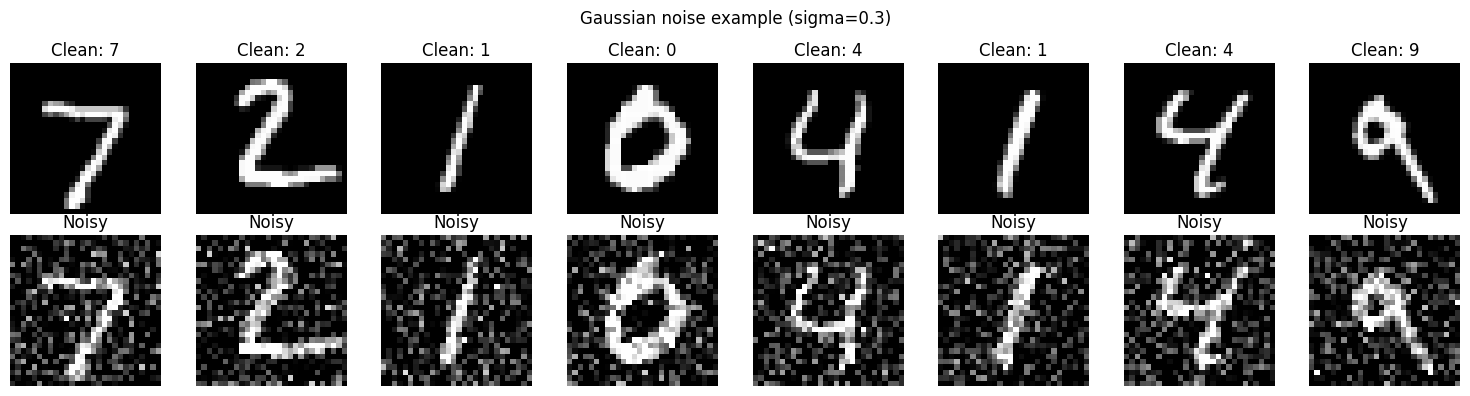

In [ ]:
# Convert uint8 to float32 and normalize every pixel to [0, 1].
x_all = x_train_raw.astype("float32") / 255.0
x_test_clean = x_test_raw.astype("float32") / 255.0

# Stratify the validation split so its digit distribution resembles the training split.
train_indices, val_indices = train_test_split(
    np.arange(len(x_all)),
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=y_train,
)

x_train_clean = x_all[train_indices]
y_train_fit = y_train[train_indices]
x_val_clean = x_all[val_indices]
y_val = y_train[val_indices]

# Train-derived weights are applied to both train and validation examples.
train_weights = class_weights[y_train_fit].astype("float32")
val_weights = class_weights[y_val].astype("float32")


def add_gaussian_noise(images, sigma, seed):
    """Add zero-mean Gaussian noise and clip pixels into [0, 1]."""
    rng = np.random.default_rng(seed)
    noise = rng.normal(loc=0.0, scale=sigma, size=images.shape).astype("float32")
    return np.clip(images + noise, 0.0, 1.0).astype("float32")

x_train_noisy = add_gaussian_noise(x_train_clean, TRAIN_NOISE_SIGMA, SEED + 1)
x_val_noisy = add_gaussian_noise(x_val_clean, TRAIN_NOISE_SIGMA, SEED + 2)
x_test_noisy = add_gaussian_noise(x_test_clean, TRAIN_NOISE_SIGMA, SEED + 3)

print("Train clean/noisy:", x_train_clean.shape, x_train_noisy.shape)
print("Validation clean/noisy:", x_val_clean.shape, x_val_noisy.shape)
print("Test clean/noisy:", x_test_clean.shape, x_test_noisy.shape)
print("Normalized pixel range:", float(x_train_noisy.min()), "to", float(x_train_noisy.max()))

fig, axes = plt.subplots(2, 8, figsize=(15, 4))
for i in range(8):
    axes[0, i].imshow(x_test_clean[i], cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Clean: {y_test[i]}")
    axes[1, i].imshow(x_test_noisy[i], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("Noisy")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Clean")
axes[1, 0].set_ylabel("Noisy")
plt.suptitle(f"Gaussian noise example (sigma={TRAIN_NOISE_SIGMA})")
plt.tight_layout()
plt.savefig(PLOT_DIR / "clean_vs_noisy.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Define the five required autoencoders

All five receive the same noisy inputs and reconstruct the clean target images. Their internal architecture or regularization differs:

- **Undercomplete:** a compact dense bottleneck smaller than the 784-pixel input.
- **Sparse:** an L1 activity penalty encourages only a small number of latent activations to be active.
- **Denoising:** a deeper dense encoder/decoder trained with noisy-to-clean pairs.
- **Convolutional:** Conv2D and upsampling layers preserve spatial structure.
- **Contractive:** a Jacobian/Frobenius-norm penalty discourages the latent representation from changing sharply for small input changes.

In [ ]:
@keras.utils.register_keras_serializable(package="MNISTDenoising")
class ContractiveDense(layers.Layer):
    """Sigmoid dense layer with the analytic contractive Jacobian penalty.

    For h = sigmoid(xW + b), ||dh/dx||_F^2 equals
    sum_j [h_j(1-h_j)]^2 * sum_i W_ij^2 for each image.
    The penalty is added to the model loss during training.
    """
    def __init__(self, units, contractive_weight=1e-4, **kwargs):
        super().__init__(**kwargs)
        self.units = int(units)
        self.contractive_weight = float(contractive_weight)

    def build(self, input_shape):
        input_dim = int(input_shape[-1])
        self.kernel = self.add_weight(
            name="kernel", shape=(input_dim, self.units),
            initializer="glorot_uniform", trainable=True,
        )
        self.bias = self.add_weight(
            name="bias", shape=(self.units,), initializer="zeros", trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs):
        preactivation = tf.matmul(inputs, self.kernel) + self.bias
        latent = tf.nn.sigmoid(preactivation)
        sigmoid_derivative = latent * (1.0 - latent)
        column_norm_squared = tf.reduce_sum(tf.square(self.kernel), axis=0)
        per_image_jacobian_norm = tf.reduce_sum(
            tf.square(sigmoid_derivative) * column_norm_squared, axis=-1
        )
        self.add_loss(self.contractive_weight * tf.reduce_mean(per_image_jacobian_norm))
        return latent

    def get_config(self):
        config = super().get_config()
        config.update({
            "units": self.units,
            "contractive_weight": self.contractive_weight,
        })
        return config


def build_undercomplete_autoencoder(latent_dim=64):
    inp = keras.Input(shape=(IMAGE_SIZE,), name="noisy_flat_image")
    x = layers.Dense(256, activation="relu", name="encoder_dense")(inp)
    z = layers.Dense(latent_dim, activation="relu", name="latent_code")(x)
    x = layers.Dense(256, activation="relu", name="decoder_dense")(z)
    out = layers.Dense(IMAGE_SIZE, activation="sigmoid", name="reconstructed_pixels")(x)
    return keras.Model(inp, out, name=f"Undercomplete_AE_{latent_dim}")


def build_sparse_autoencoder(latent_dim=128, l1_strength=1e-5):
    inp = keras.Input(shape=(IMAGE_SIZE,), name="noisy_flat_image")
    x = layers.Dense(256, activation="relu")(inp)
    z = layers.Dense(
        latent_dim,
        activation="sigmoid",
        activity_regularizer=regularizers.l1(l1_strength),
        name="sparse_latent_code",
    )(x)
    x = layers.Dense(256, activation="relu")(z)
    out = layers.Dense(IMAGE_SIZE, activation="sigmoid")(x)
    return keras.Model(inp, out, name="Sparse_AE")


def build_denoising_autoencoder(latent_dim=128):
    inp = keras.Input(shape=(IMAGE_SIZE,), name="noisy_flat_image")
    x = layers.Dense(512, activation="relu")(inp)
    x = layers.Dropout(0.10)(x)
    x = layers.Dense(256, activation="relu")(x)
    z = layers.Dense(latent_dim, activation="relu", name="latent_code")(x)
    x = layers.Dense(256, activation="relu")(z)
    x = layers.Dense(512, activation="relu")(x)
    out = layers.Dense(IMAGE_SIZE, activation="sigmoid")(x)
    return keras.Model(inp, out, name="Denoising_AE")


def build_convolutional_autoencoder():
    inp = keras.Input(shape=(IMAGE_H, IMAGE_W, 1), name="noisy_image")
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)
    x = layers.MaxPooling2D(2, padding="same")(x)          # 14 x 14
    x = layers.Conv2D(16, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, padding="same")(x)          # 7 x 7
    z = layers.Conv2D(8, 3, activation="relu", padding="same", name="conv_latent")(x)
    x = layers.UpSampling2D(2)(z)                           # 14 x 14
    x = layers.Conv2D(16, 3, activation="relu", padding="same")(x)
    x = layers.UpSampling2D(2)(x)                           # 28 x 28
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    out = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)
    return keras.Model(inp, out, name="Convolutional_AE")


def build_contractive_autoencoder(latent_dim=128, contractive_weight=1e-4):
    inp = keras.Input(shape=(IMAGE_SIZE,), name="noisy_flat_image")
    z = ContractiveDense(
        latent_dim, contractive_weight=contractive_weight,
        name="contractive_latent_code",
    )(inp)
    x = layers.Dense(256, activation="relu")(z)
    out = layers.Dense(IMAGE_SIZE, activation="sigmoid")(x)
    return keras.Model(inp, out, name="Contractive_AE")


MODEL_BUILDERS = {
    "Undercomplete AE": build_undercomplete_autoencoder,
    "Sparse AE": build_sparse_autoencoder,
    "Denoising AE": build_denoising_autoencoder,
    "Convolutional AE": build_convolutional_autoencoder,
    "Contractive AE": build_contractive_autoencoder,
}

# Print all architectures and trainable parameter counts.
for model_name, builder in MODEL_BUILDERS.items():
    model = builder()
    print("\n" + "=" * 85)
    print(model_name)
    model.summary()
    print("Trainable parameters:", model.count_params())
    del model
    gc.collect()


Undercomplete AE


Model: "Undercomplete_AE_64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noisy_flat_image (InputLayer)   │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense (Dense)           │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_code (Dense)             │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense (Dense)           │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_pixels (Dense)    │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 435,536 (1.66 MB)

 Trainable params: 435,536 (1.66 MB)

 Non-trainable params: 0 (0.00 B)

... (21 outputs left out)

 Total params: 334,992 (1.28 MB)

 Trainable params: 334,992 (1.28 MB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 334992


## 5. Build data pipelines and train all five models

In [ ]:
def model_arrays(model_name, noisy_images, clean_images):
    """Return model-shaped input and target arrays."""
    if model_name == "Convolutional AE":
        return noisy_images[..., np.newaxis], clean_images[..., np.newaxis]
    return noisy_images.reshape(-1, IMAGE_SIZE), clean_images.reshape(-1, IMAGE_SIZE)


def make_dataset(x, y, weights=None, shuffle=False):
    if weights is not None:
        # Match sample weight dimensions to target dimensions to prevent broadcasting shape mismatch
        target_ndims = len(y.shape)
        if target_ndims > 1:
            reshaped_weights = weights.reshape((-1,) + (1,) * (target_ndims - 1))
        else:
            reshaped_weights = weights
        ds = tf.data.Dataset.from_tensor_slices((x, y, reshaped_weights))
    else:
        ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        ds = ds.shuffle(min(len(x), 20000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_seconds = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_seconds.append(time.perf_counter() - self.epoch_start)


trained_models = {}
histories = {}
training_records = []

for model_name, builder in MODEL_BUILDERS.items():
    print("\n" + "#" * 90)
    print("Training:", model_name)

    xtr, ytr = model_arrays(model_name, x_train_noisy, x_train_clean)
    xva, yva = model_arrays(model_name, x_val_noisy, x_val_clean)
    train_ds = make_dataset(xtr, ytr, train_weights, shuffle=True)
    val_ds = make_dataset(xva, yva, val_weights, shuffle=False)

    model = builder()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )

    timer = EpochTimer()
    callbacks = [
        timer,
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
        ),
    ]

    start = time.perf_counter()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )
    total_seconds = time.perf_counter() - start

    trained_models[model_name] = model
    histories[model_name] = history.history
    training_records.append({
        "Model": model_name,
        "Parameters": int(model.count_params()),
        "Epochs trained": len(history.history["loss"]),
        "Train time (sec)": total_seconds,
        "Average epoch (sec)": float(np.mean(timer.epoch_seconds)) if timer.epoch_seconds else np.nan,
        "Approx. float32 weights (MB)": model.count_params() * 4 / (1024 ** 2),
    })

    print(f"Completed in {total_seconds / 60:.2f} minutes")
    del train_ds, val_ds, xtr, ytr, xva, yva
    gc.collect()

training_table = pd.DataFrame(training_records)
display(training_table)
training_table.to_csv(RESULT_DIR / "training_costs.csv", index=False)


##########################################################################################
Training: Undercomplete AE
Epoch 1/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - loss: 0.0562 - mae: 0.1181 - val_loss: 0.0319 - val_mae: 0.0762 - learning_rate: 0.0010
Epoch 2/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0255 - mae: 0.0652 - val_loss: 0.0211 - val_mae: 0.0575 - learning_rate: 0.0010
Epoch 3/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 0.0192 - mae: 0.0537 - val_loss: 0.0177 - val_mae: 0.0507 - learning_rate: 0.0010
Epoch 4/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - loss: 0.0165 - mae: 0.0488 - val_loss: 0.0156 - val_mae: 0.0472 - learning_rate: 0.0010
Epoch 5/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 0.0148 - mae: 0.0455 - val_loss: 0.0143 - val_mae: 0.0443 - learning_rate: 0.0010
Epoch 6/15
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - loss: 0.0136 - mae: 0.0432 - val_loss: 0.0132 - val_mae: 0.0419 - learning_rate: 0.0010
Epoch 7/15
211/211 ━━━━

,Model,Parameters,Epochs trained,Train time (sec),Average epoch (sec),Approx. float32 weights (MB)
0,Undercomplete AE,435536,15,105.415470,7.017300,1.661438
1,Sparse AE,468368,15,114.434524,7.461317,1.786682
2,Denoising AE,1132944,15,253.019077,16.855556,4.321838
3,Convolutional AE,12201,9,1582.731622,175.847789,0.046543
4,Contractive AE,334992,15,120.521804,7.812752,1.277893


## 6. Plot training and validation loss

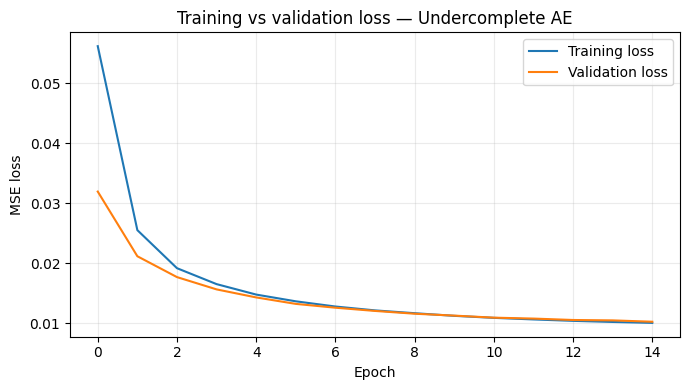

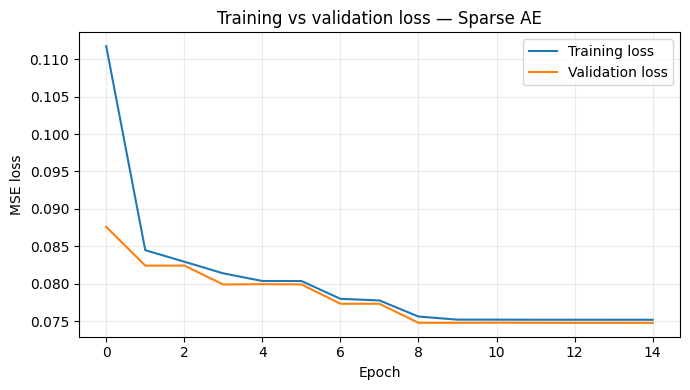

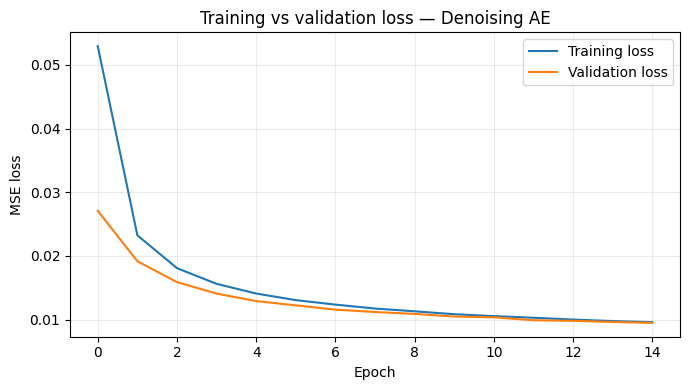

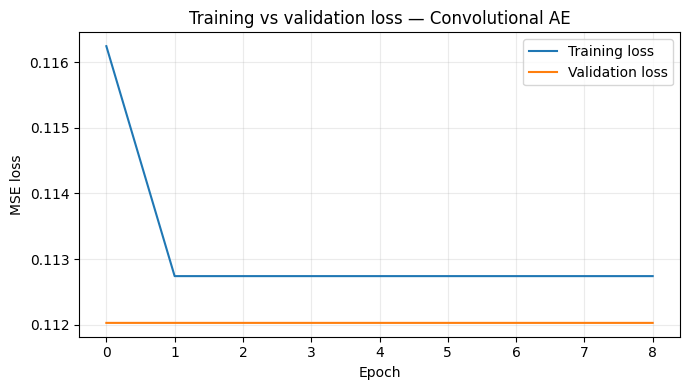

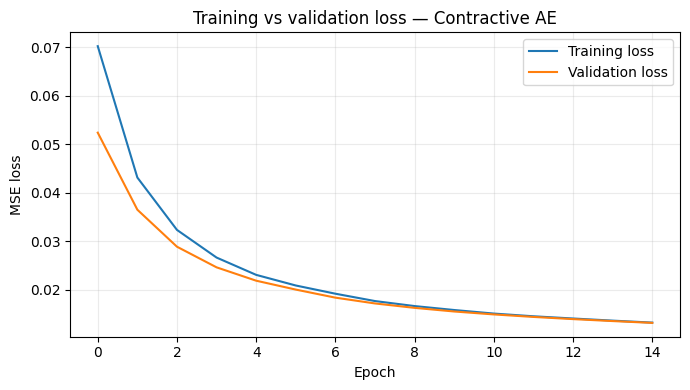

In [ ]:
for model_name, history in histories.items():
    plt.figure(figsize=(7, 4))
    plt.plot(history["loss"], label="Training loss")
    plt.plot(history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")
    plt.title(f"Training vs validation loss — {model_name}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(PLOT_DIR / f"loss_{safe_name}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 7. Quantitative evaluation: MSE, MAE, PSNR, and SSIM

,Model,MSE,MAE,PSNR (dB),SSIM
0,Denoising AE,0.009396,0.033323,20.736771,0.872504
1,Undercomplete AE,0.010128,0.035650,20.373024,0.834312
2,Contractive AE,0.012220,0.042818,19.559490,0.796180
3,Sparse AE,0.066969,0.150837,11.890546,0.114748
4,Convolutional AE,0.111365,0.129976,9.829512,0.099326


Evaluating: Undercomplete AE
Evaluating: Sparse AE
Evaluating: Denoising AE
Evaluating: Convolutional AE
Evaluating: Contractive AE


,Model,MSE,MAE,PSNR (dB),SSIM
0,Denoising AE,0.009198,0.032862,20.823048,0.876258
1,Undercomplete AE,0.009830,0.035029,20.497526,0.840927
2,Contractive AE,0.011865,0.042166,19.689310,0.803623
3,Sparse AE,0.067467,0.151349,11.858430,0.118833
4,Convolutional AE,0.113958,0.132518,9.730679,0.095574


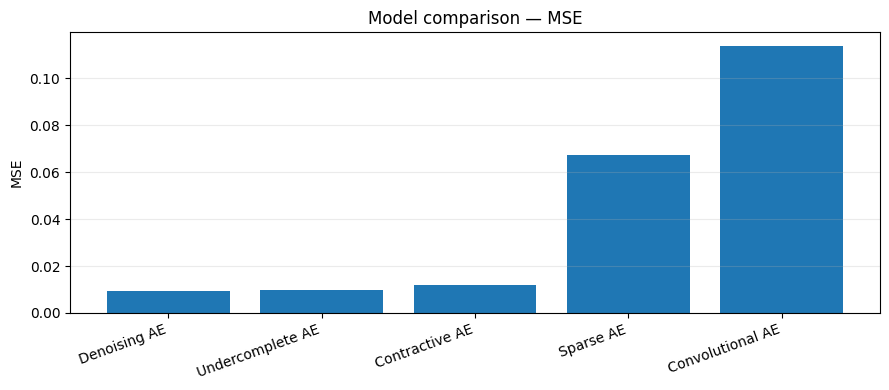

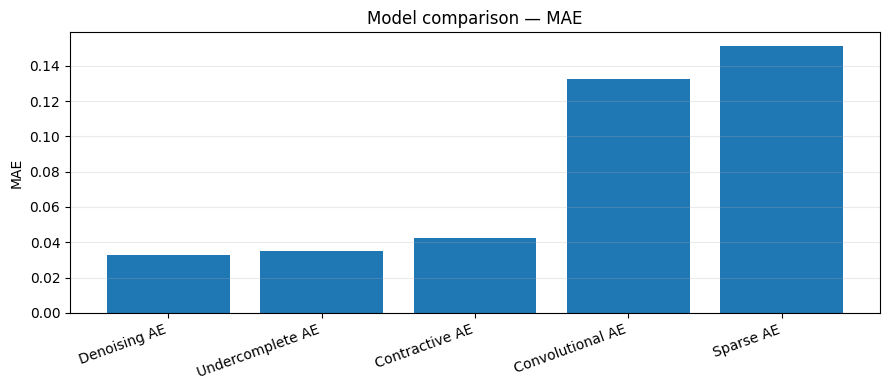

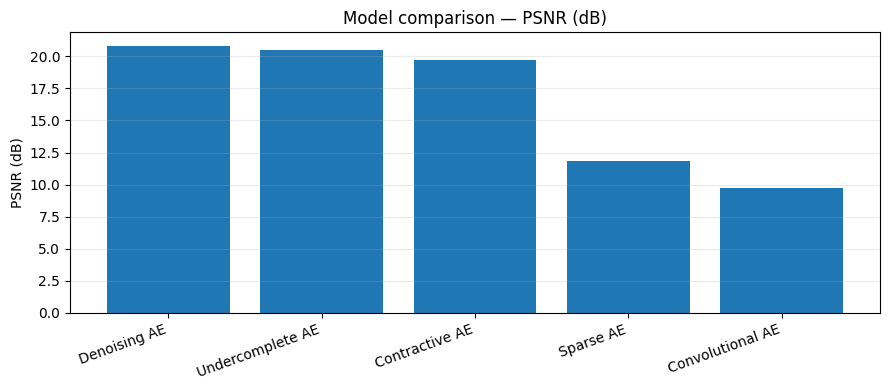

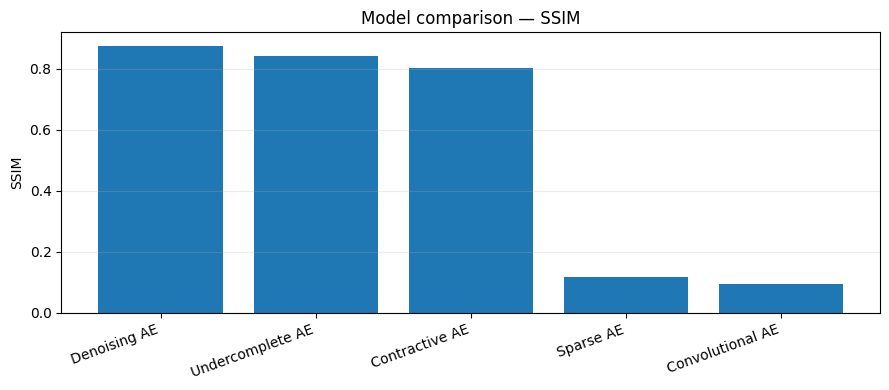

In [ ]:
def predict_images(model, model_name, noisy_images, batch_size=512):
    x_input, _ = model_arrays(model_name, noisy_images, noisy_images)
    predictions = model.predict(x_input, batch_size=batch_size, verbose=0)
    predictions = predictions.reshape(-1, IMAGE_H, IMAGE_W)
    return np.clip(predictions, 0.0, 1.0).astype("float32")


def denoising_metrics(clean_images, predicted_images):
    clean_4d = clean_images[..., np.newaxis].astype("float32")
    pred_4d = predicted_images[..., np.newaxis].astype("float32")
    mse = np.mean(np.square(clean_4d - pred_4d), axis=(1, 2, 3))
    mae = np.mean(np.abs(clean_4d - pred_4d), axis=(1, 2, 3))
    psnr = tf.image.psnr(clean_4d, pred_4d, max_val=1.0).numpy()
    ssim = tf.image.ssim(clean_4d, pred_4d, max_val=1.0).numpy()
    return {
        "MSE": float(np.mean(mse)),
        "MAE": float(np.mean(mae)),
        "PSNR (dB)": float(np.mean(psnr)),
        "SSIM": float(np.mean(ssim)),
    }


# Select the deployment model on validation data, not on the final test set.
validation_records = []
for model_name, model in trained_models.items():
    val_prediction = predict_images(model, model_name, x_val_noisy)
    validation_records.append({"Model": model_name, **denoising_metrics(x_val_clean, val_prediction)})

validation_table = pd.DataFrame(validation_records).sort_values(
    ["SSIM", "PSNR (dB)"], ascending=[False, False]
).reset_index(drop=True)
display(validation_table)
validation_table.to_csv(RESULT_DIR / "validation_model_selection.csv", index=False)

baseline_predictions = {}
evaluation_records = []
for model_name, model in trained_models.items():
    print("Evaluating:", model_name)
    prediction = predict_images(model, model_name, x_test_noisy)
    baseline_predictions[model_name] = prediction
    row = {"Model": model_name, **denoising_metrics(x_test_clean, prediction)}
    evaluation_records.append(row)

evaluation_table = pd.DataFrame(evaluation_records).sort_values(
    ["SSIM", "PSNR (dB)"], ascending=[False, False]
).reset_index(drop=True)
display(evaluation_table)
evaluation_table.to_csv(RESULT_DIR / "baseline_evaluation.csv", index=False)

# Separate charts avoid hiding differences caused by the different metric scales.
for metric in ["MSE", "MAE", "PSNR (dB)", "SSIM"]:
    plot_df = evaluation_table.sort_values(metric, ascending=(metric in ["MSE", "MAE"]))
    plt.figure(figsize=(9, 4))
    plt.bar(plot_df["Model"], plot_df[metric])
    plt.xticks(rotation=20, ha="right")
    plt.ylabel(metric)
    plt.title(f"Model comparison — {metric}")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"comparison_{metric.lower().replace(' ', '_').replace('(', '').replace(')', '')}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 8. Visual denoising comparison (10 examples for every model)

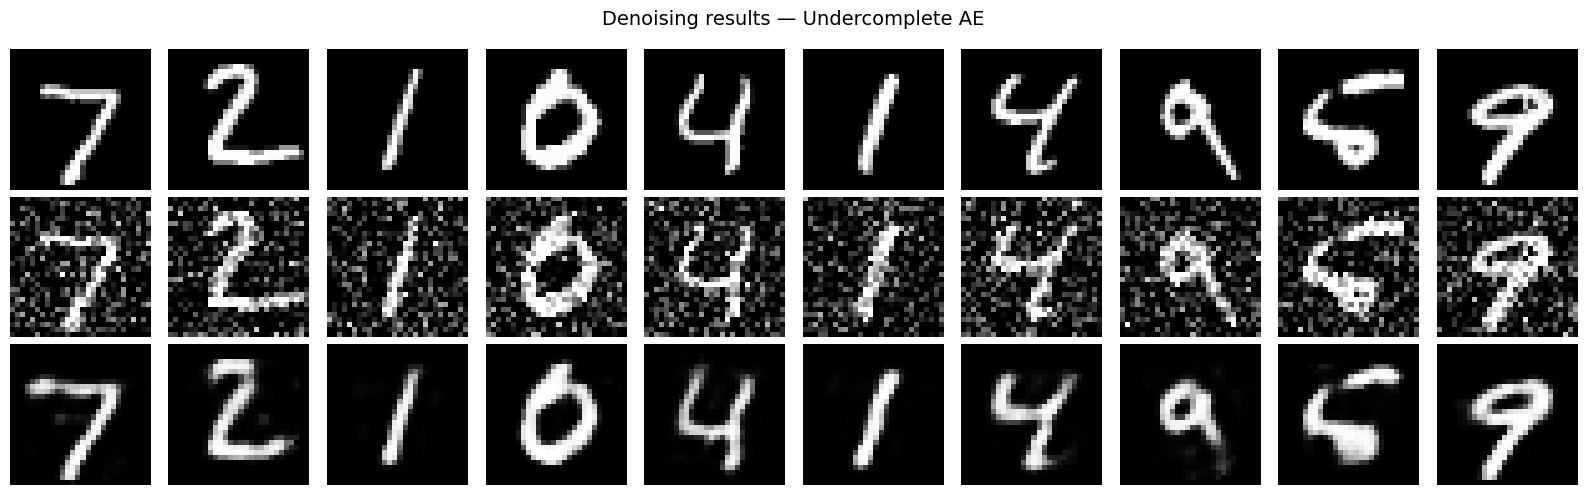

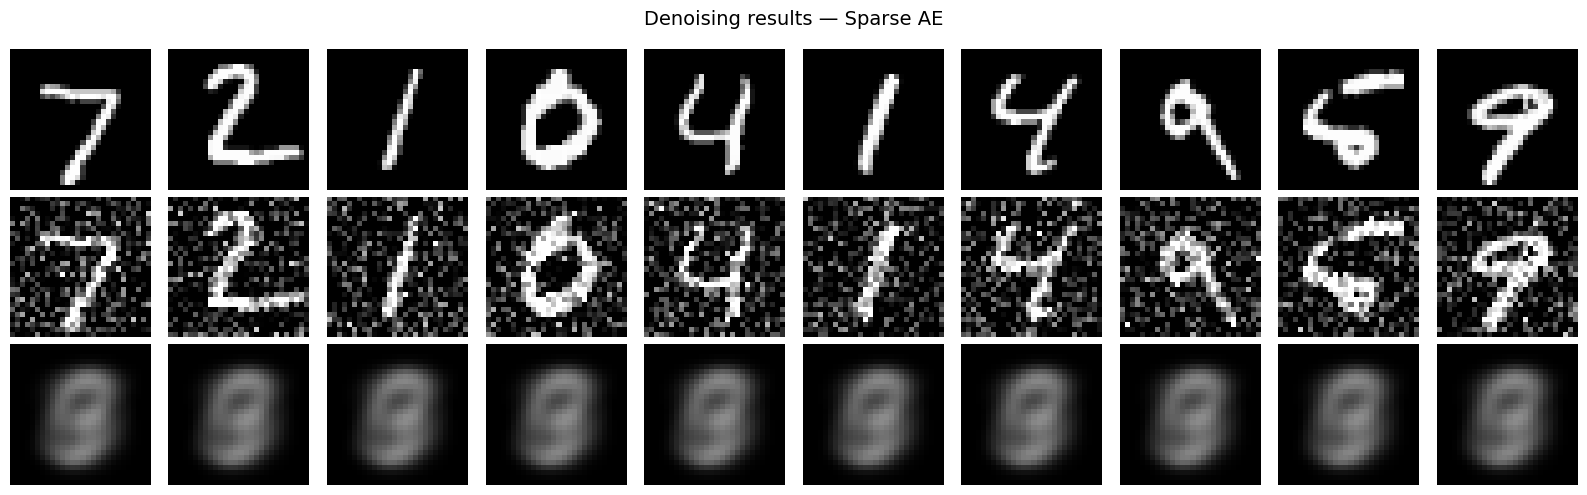

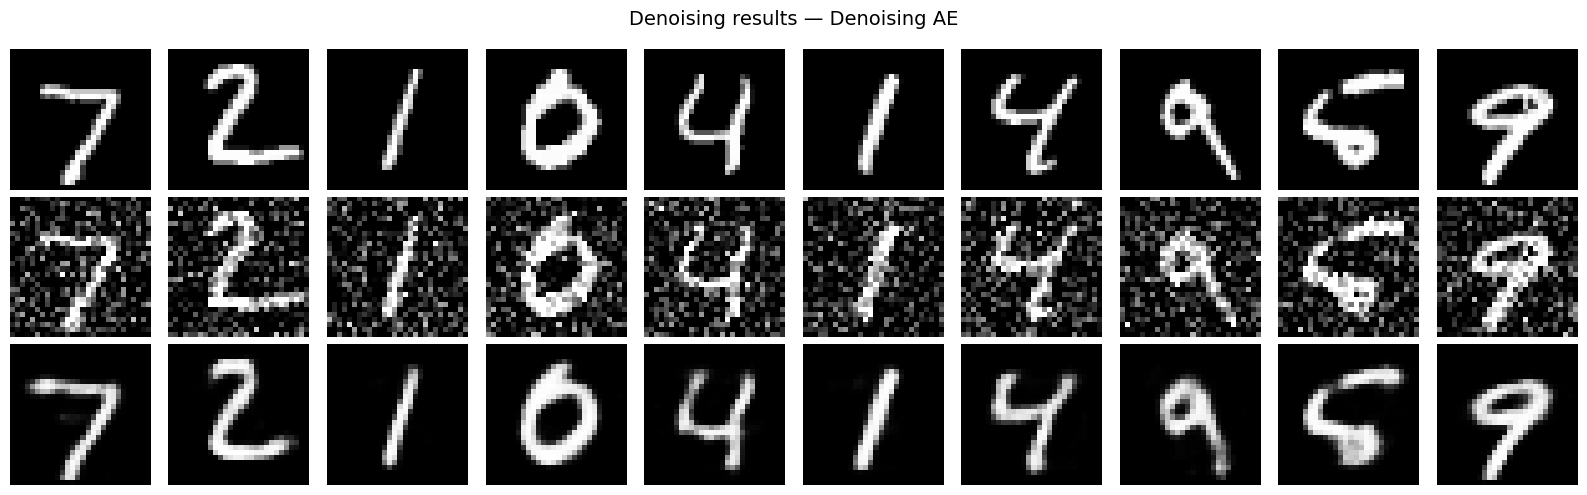

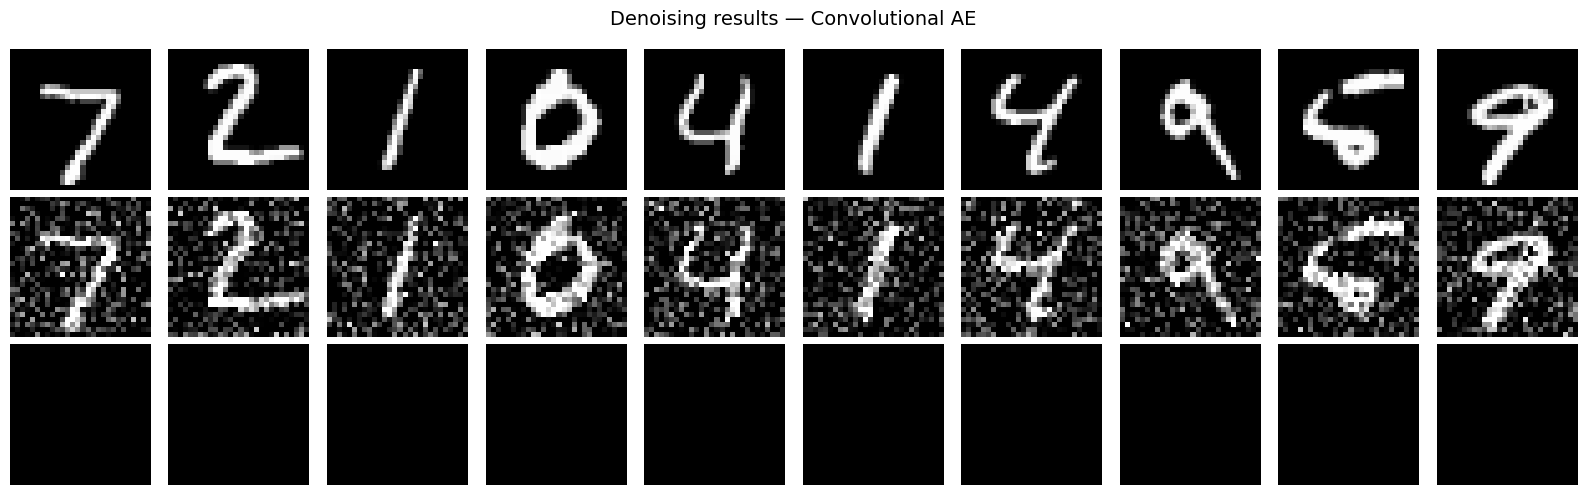

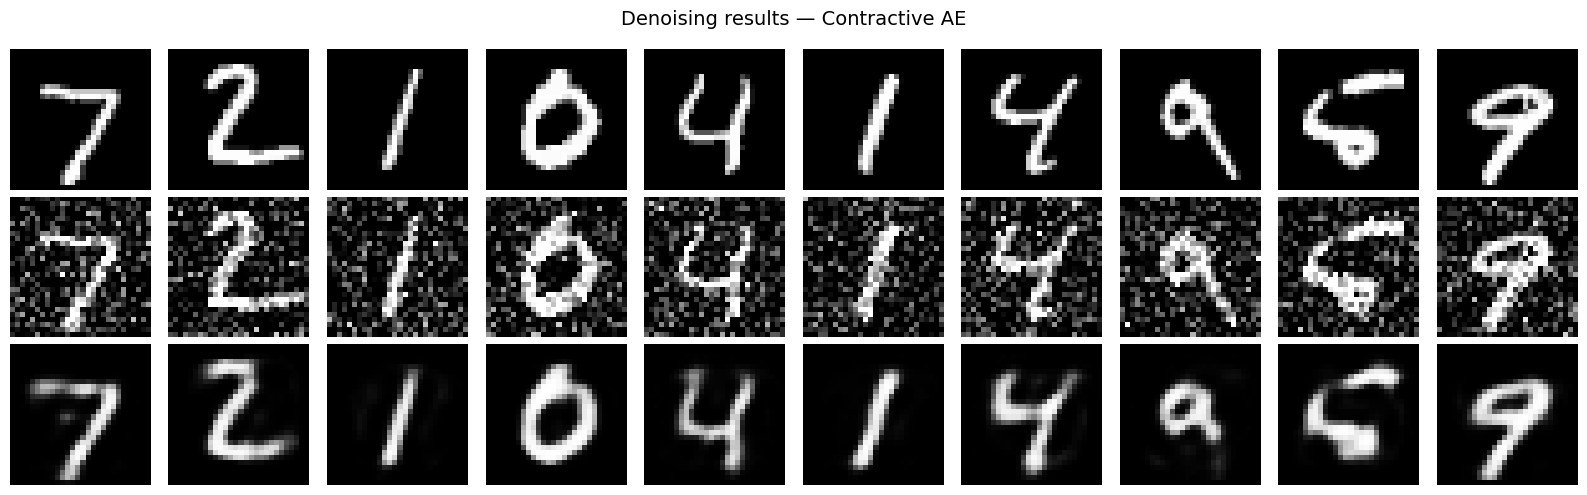

In [ ]:
NUM_VISUAL_EXAMPLES = 10
for model_name, prediction in baseline_predictions.items():
    fig, axes = plt.subplots(3, NUM_VISUAL_EXAMPLES, figsize=(16, 5))
    for i in range(NUM_VISUAL_EXAMPLES):
        axes[0, i].imshow(x_test_clean[i], cmap="gray", vmin=0, vmax=1)
        axes[1, i].imshow(x_test_noisy[i], cmap="gray", vmin=0, vmax=1)
        axes[2, i].imshow(prediction[i], cmap="gray", vmin=0, vmax=1)
        for row in range(3):
            axes[row, i].axis("off")
    axes[0, 0].set_ylabel("Original", fontsize=10)
    axes[1, 0].set_ylabel("Noisy", fontsize=10)
    axes[2, 0].set_ylabel("Denoised", fontsize=10)
    fig.suptitle(f"Denoising results — {model_name}", fontsize=14)
    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(PLOT_DIR / f"reconstructions_{safe_name}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 9. Noise-level experiment (sigma = 0.1, 0.2, 0.3, 0.4, 0.5)

,Noise sigma,Model,MSE,MAE,PSNR (dB),SSIM
0,0.1,Undercomplete AE,0.008117,0.032213,21.385452,0.874710
1,0.1,Sparse AE,0.067439,0.151266,11.861155,0.118897
2,0.1,Denoising AE,0.010494,0.033962,20.202744,0.864625
3,0.1,Convolutional AE,0.113959,0.132568,9.730640,0.095574
4,0.1,Contractive AE,0.009941,0.035674,20.575727,0.868011
5,0.2,Undercomplete AE,0.008201,0.031859,21.356289,0.870613
6,0.2,Sparse AE,0.067464,0.151341,11.858682,0.118839
7,0.2,Denoising AE,0.008523,0.030834,21.193502,0.886392
8,0.2,Convolutional AE,0.113958,0.132528,9.730676,0.095574
9,0.2,Contractive AE,0.010298,0.037638,20.398329,0.847078


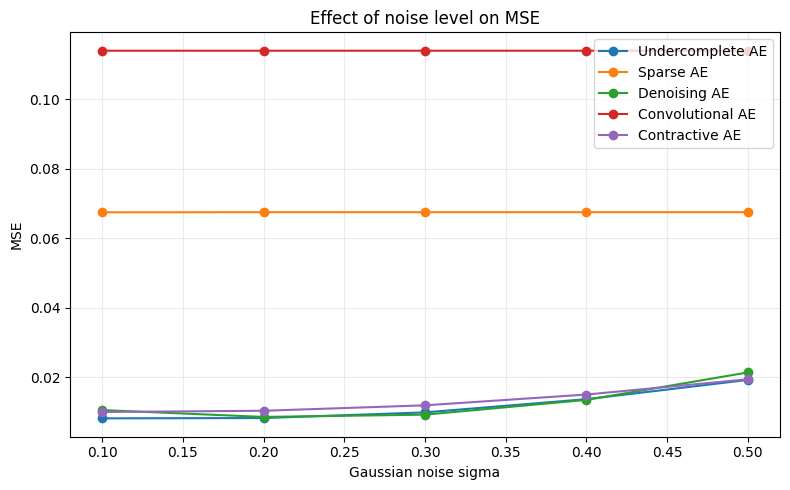

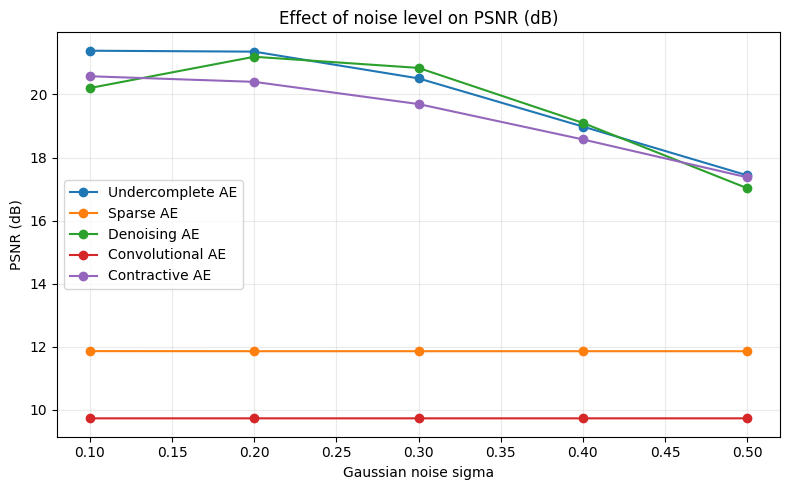

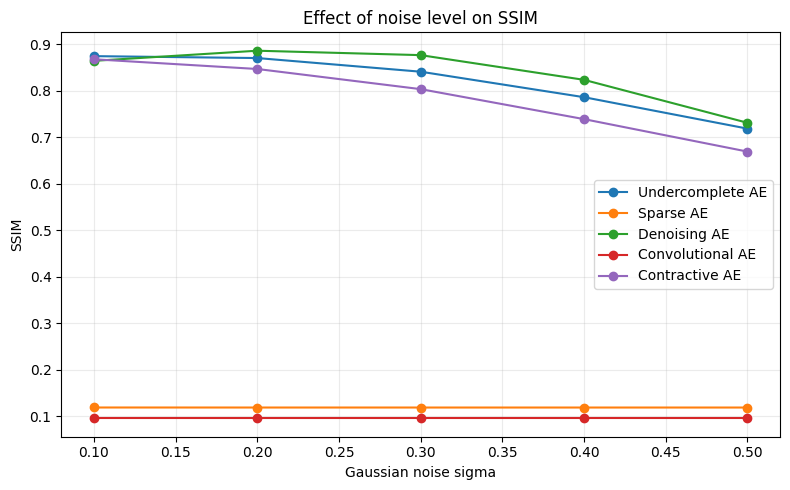

In [ ]:
noise_records = []
for sigma in NOISE_LEVELS:
    noisy_at_level = add_gaussian_noise(x_test_clean, sigma, SEED + int(sigma * 1000))
    for model_name, model in trained_models.items():
        pred = predict_images(model, model_name, noisy_at_level)
        noise_records.append({
            "Noise sigma": sigma,
            "Model": model_name,
            **denoising_metrics(x_test_clean, pred),
        })

noise_table = pd.DataFrame(noise_records)
display(noise_table)
noise_table.to_csv(RESULT_DIR / "noise_level_evaluation.csv", index=False)

for metric in ["MSE", "PSNR (dB)", "SSIM"]:
    plt.figure(figsize=(8, 5))
    for model_name in MODEL_BUILDERS:
        subset = noise_table[noise_table["Model"] == model_name].sort_values("Noise sigma")
        plt.plot(subset["Noise sigma"], subset[metric], marker="o", label=model_name)
    plt.xlabel("Gaussian noise sigma")
    plt.ylabel(metric)
    plt.title(f"Effect of noise level on {metric}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"noise_level_{metric.lower().replace(' ', '_').replace('(', '').replace(')', '')}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 10. Latent-dimension experiment

The latent-dimension sweep is performed on the undercomplete dense autoencoder, where the latent dimension is directly controlled. The convolutional model has a spatial latent tensor instead of a single dense latent-size parameter, so this sweep is not directly comparable to its latent representation.


Training undercomplete AE with latent dimension = 8
Epoch 1/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 14s 44ms/step - loss: 0.0642 - val_loss: 0.0430 - learning_rate: 0.0010
Epoch 2/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0387 - val_loss: 0.0357 - learning_rate: 0.0010
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0344 - val_loss: 0.0330 - learning_rate: 0.0010
Epoch 4/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - loss: 0.0324 - val_loss: 0.0316 - learning_rate: 0.0010
Epoch 5/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0311 - val_loss: 0.0306 - learning_rate: 0.0010
Epoch 6/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0302 - val_loss: 0.0298 - learning_rate: 0.0010
Epoch 7/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - loss: 0.0294 - val_loss: 0.0292 - learning_rate: 0.0010
Epoch 8/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0288 - val_loss: 0.0285 - learning_rate: 0.0010
Epoch 9/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - los

,Latent dimension,Parameters,Epochs trained,Train time (sec),MSE,MAE,PSNR (dB),SSIM
0,8,406808,10,65.746316,0.027067,0.070025,16.275904,0.640818
1,16,410912,10,60.041815,0.019782,0.055527,17.634747,0.737340
2,32,419120,10,70.784599,0.016546,0.049108,18.355541,0.774870
3,64,435536,10,73.081602,0.011295,0.038316,19.910543,0.828432
4,128,468368,10,75.743802,0.009758,0.035527,20.510971,0.824194


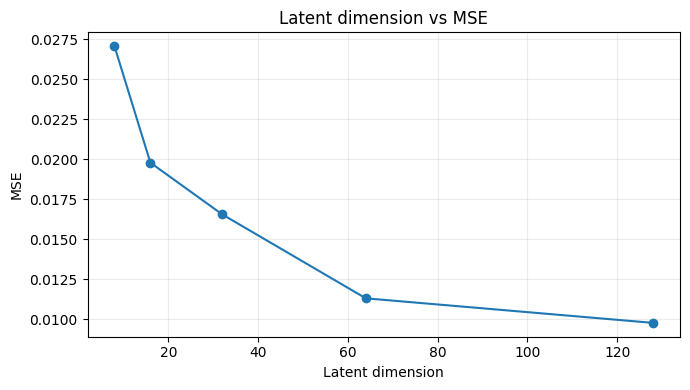

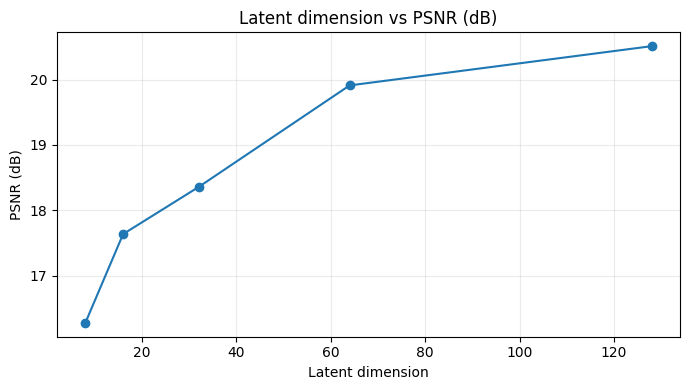

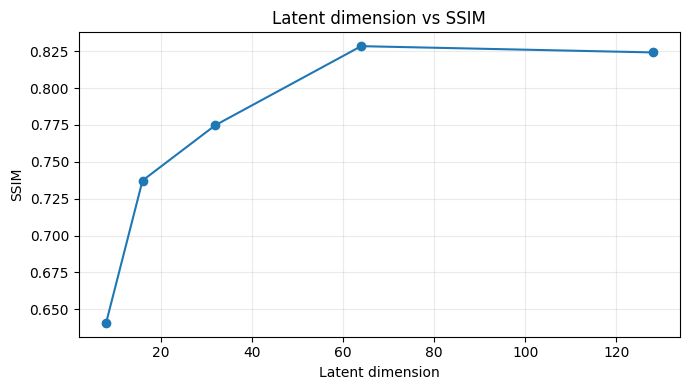

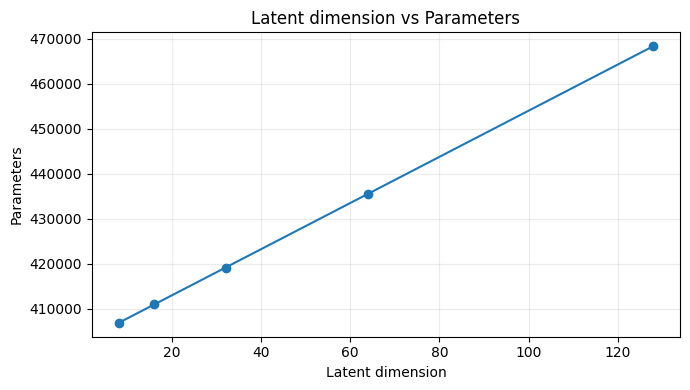

In [ ]:
latent_records = []
latent_histories = {}
for latent_dim in LATENT_DIMS:
    print(f"\nTraining undercomplete AE with latent dimension = {latent_dim}")
    xtr, ytr = model_arrays("Undercomplete AE", x_train_noisy, x_train_clean)
    xva, yva = model_arrays("Undercomplete AE", x_val_noisy, x_val_clean)
    train_ds = make_dataset(xtr, ytr, train_weights, shuffle=True)
    val_ds = make_dataset(xva, yva, val_weights, shuffle=False)

    latent_model = build_undercomplete_autoencoder(latent_dim=latent_dim)
    latent_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="mse",
    )
    start = time.perf_counter()
    hist = latent_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=LATENT_EPOCHS,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=3, restore_best_weights=True
            ),
            keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
            ),
        ],
        verbose=1,
    )
    train_seconds = time.perf_counter() - start
    pred = predict_images(latent_model, "Undercomplete AE", x_test_noisy)
    latent_records.append({
        "Latent dimension": latent_dim,
        "Parameters": int(latent_model.count_params()),
        "Epochs trained": len(hist.history["loss"]),
        "Train time (sec)": train_seconds,
        **denoising_metrics(x_test_clean, pred),
    })
    latent_histories[latent_dim] = hist.history

    del latent_model, train_ds, val_ds, xtr, ytr, xva, yva, pred
    gc.collect()

latent_table = pd.DataFrame(latent_records)
display(latent_table)
latent_table.to_csv(RESULT_DIR / "latent_dimension_evaluation.csv", index=False)

for metric in ["MSE", "PSNR (dB)", "SSIM", "Parameters"]:
    plt.figure(figsize=(7, 4))
    plt.plot(latent_table["Latent dimension"], latent_table[metric], marker="o")
    plt.xlabel("Latent dimension")
    plt.ylabel(metric)
    plt.title(f"Latent dimension vs {metric}")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"latent_dimension_{metric.lower().replace(' ', '_').replace('(', '').replace(')', '')}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 11. Computational comparison and error/visual inspection

,Model,MSE,MAE,PSNR (dB),SSIM,Parameters,Epochs trained,Train time (sec),Average epoch (sec),Approx. float32 weights (MB),Inference time for 1000 (sec),Average inference (ms/image)
0,Denoising AE,0.009198,0.032862,20.823048,0.876258,1132944,15,253.019077,16.855556,4.321838,0.155127,0.155127
1,Undercomplete AE,0.009830,0.035029,20.497526,0.840927,435536,15,105.415470,7.017300,1.661438,0.139371,0.139371
2,Contractive AE,0.011865,0.042166,19.689310,0.803623,334992,15,120.521804,7.812752,1.277893,0.245404,0.245404
3,Sparse AE,0.067467,0.151349,11.858430,0.118833,468368,15,114.434524,7.461317,1.786682,0.180413,0.180413
4,Convolutional AE,0.113958,0.132518,9.730679,0.095574,12201,9,1582.731622,175.847789,0.046543,1.368108,1.368108


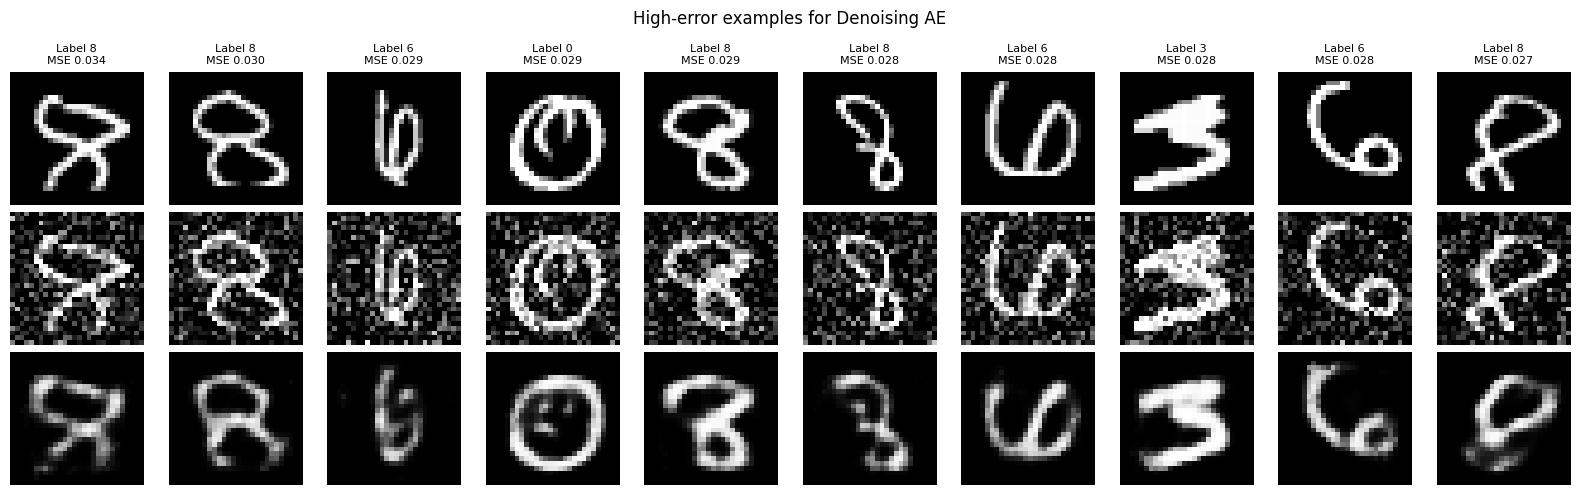

Best model by validation SSIM, with validation PSNR as tie-breaker: Denoising AE
Selection uses validation metrics. Final test metrics remain for reporting; inspect the images before claiming it is universally best.


In [ ]:
# Measure inference time on 1,000 test images after a warm-up call.
inference_records = []
for model_name, model in trained_models.items():
    x_sample, _ = model_arrays(model_name, x_test_noisy[:1000], x_test_clean[:1000])
    _ = model.predict(x_sample[:min(32, len(x_sample))], verbose=0)  # warm-up
    start = time.perf_counter()
    _ = model.predict(x_sample, batch_size=256, verbose=0)
    elapsed = time.perf_counter() - start
    inference_records.append({
        "Model": model_name,
        "Inference time for 1000 (sec)": elapsed,
        "Average inference (ms/image)": elapsed / len(x_sample) * 1000,
    })

inference_table = pd.DataFrame(inference_records)
comparison_table = evaluation_table.merge(training_table, on="Model").merge(inference_table, on="Model")
display(comparison_table)
comparison_table.to_csv(RESULT_DIR / "complete_model_comparison.csv", index=False)

# Show selected examples where the best model makes relatively large pixel errors.
best_model_name = validation_table.iloc[0]["Model"]
best_predictions = baseline_predictions[best_model_name]
per_image_mse = np.mean((x_test_clean - best_predictions) ** 2, axis=(1, 2))
worst_indices = np.argsort(per_image_mse)[-10:][::-1]

fig, axes = plt.subplots(3, 10, figsize=(16, 5))
for col, idx in enumerate(worst_indices):
    axes[0, col].imshow(x_test_clean[idx], cmap="gray", vmin=0, vmax=1)
    axes[1, col].imshow(x_test_noisy[idx], cmap="gray", vmin=0, vmax=1)
    axes[2, col].imshow(best_predictions[idx], cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(f"Label {y_test[idx]}\nMSE {per_image_mse[idx]:.3f}", fontsize=8)
    for row in range(3):
        axes[row, col].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Noisy")
axes[2, 0].set_ylabel("Denoised")
plt.suptitle(f"High-error examples for {best_model_name}")
plt.tight_layout()
plt.savefig(PLOT_DIR / "best_model_high_error_examples.png", dpi=160, bbox_inches="tight")
plt.show()

print("Best model by validation SSIM, with validation PSNR as tie-breaker:", best_model_name)
print("Selection uses validation metrics. Final test metrics remain for reporting; inspect the images before claiming it is universally best.")

## 12. Save the selected model and deployment metadata

In [ ]:
best_model = trained_models[best_model_name]
best_model_path = MODEL_DIR / "best_mnist_denoiser.keras"
best_model.save(best_model_path)

metadata = {
    "model_name": best_model_name,
    "model_file": "best_mnist_denoiser.keras",
    "input_height": IMAGE_H,
    "input_width": IMAGE_W,
    "channels": 1,
    "normalization": "grayscale float32 pixels divided by 255, range [0, 1]",
    "training_noise_sigma": TRAIN_NOISE_SIGMA,
    "selection_rule": "Highest validation SSIM at the baseline noise level; validation PSNR used as tie-breaker",
    "validation_selection_metrics": validation_table.loc[validation_table["Model"] == best_model_name].iloc[0].to_dict(),
    "final_test_metrics": evaluation_table.loc[evaluation_table["Model"] == best_model_name].iloc[0].to_dict(),
}
with open(OUTPUT_DIR / "best_model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved model:", best_model_path.resolve())
print("Metadata:", (OUTPUT_DIR / "best_model_metadata.json").resolve())

Saved model: /content/outputs/models/best_mnist_denoiser.keras
Metadata: /content/outputs/best_model_metadata.json


## 13. Deployment: generate a Streamlit application

In [ ]:
# This cell writes app.py into the current project folder.
app_source = r'''import json
from pathlib import Path

import numpy as np
import streamlit as st
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image, ImageOps

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "outputs" / "models" / "best_mnist_denoiser.keras"
METADATA_PATH = BASE_DIR / "outputs" / "best_model_metadata.json"

@keras.utils.register_keras_serializable(package="MNISTDenoising")
class ContractiveDense(layers.Layer):
    def __init__(self, units, contractive_weight=1e-4, **kwargs):
        super().__init__(**kwargs)
        self.units = int(units)
        self.contractive_weight = float(contractive_weight)

    def build(self, input_shape):
        input_dim = int(input_shape[-1])
        self.kernel = self.add_weight(
            name="kernel", shape=(input_dim, self.units),
            initializer="glorot_uniform", trainable=True,
        )
        self.bias = self.add_weight(
            name="bias", shape=(self.units,), initializer="zeros", trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs):
        latent = tf.nn.sigmoid(tf.matmul(inputs, self.kernel) + self.bias)
        derivative = latent * (1.0 - latent)
        column_norm_squared = tf.reduce_sum(tf.square(self.kernel), axis=0)
        penalty = tf.reduce_sum(tf.square(derivative) * column_norm_squared, axis=-1)
        self.add_loss(self.contractive_weight * tf.reduce_mean(penalty))
        return latent

    def get_config(self):
        config = super().get_config()
        config.update({"units": self.units, "contractive_weight": self.contractive_weight})
        return config


@st.cache_resource
def load_denoiser():
    if not MODEL_PATH.exists():
        raise FileNotFoundError(
            f"Trained model not found at {MODEL_PATH}. Run the notebook through the model-saving section first."
        )
    return keras.models.load_model(
        MODEL_PATH,
        custom_objects={"ContractiveDense": ContractiveDense},
        compile=False,
    )


def preprocess_uploaded_image(uploaded_file):
    """Convert a single digit image to 28x28 MNIST-like grayscale format.

    Expected convention: bright digit on a dark background, as in MNIST.
    Bright paper backgrounds are inverted automatically using the border brightness.
    For best results upload a single, roughly centered digit, preferably already noisy.
    """
    image = Image.open(uploaded_file).convert("L")
    image = ImageOps.autocontrast(image)
    arr = np.asarray(image, dtype=np.float32) / 255.0

    border = np.concatenate([arr[0, :], arr[-1, :], arr[:, 0], arr[:, -1]])
    if float(np.mean(border)) > 0.5:
        arr = 1.0 - arr

    # Resize directly to the model's fixed input size.
    resized = Image.fromarray(np.uint8(np.clip(arr, 0, 1) * 255)).resize(
        (28, 28), Image.Resampling.LANCZOS
    )
    result = np.asarray(resized, dtype=np.float32) / 255.0
    return np.clip(result, 0.0, 1.0)


st.set_page_config(page_title="MNIST Image Denoiser", page_icon="🧹", layout="centered")
st.title("MNIST Image Denoiser")
st.write("Upload a single noisy handwritten digit image. The trained autoencoder will reconstruct a cleaner 28×28 image.")

if METADATA_PATH.exists():
    with open(METADATA_PATH, "r", encoding="utf-8") as f:
        metadata = json.load(f)
    st.caption(f"Selected model: {metadata.get('model_name', 'Autoencoder')} · Training noise σ={metadata.get('training_noise_sigma', 'N/A')}")

uploaded = st.file_uploader("Choose a noisy digit image", type=["png", "jpg", "jpeg", "bmp"])

if uploaded is not None:
    try:
        prepared = preprocess_uploaded_image(uploaded)
        model = load_denoiser()
        model_name = metadata.get("model_name", "") if METADATA_PATH.exists() else ""

        if model_name == "Convolutional AE":
            model_input = prepared[np.newaxis, ..., np.newaxis]
        else:
            model_input = prepared.reshape(1, 784)

        denoised = model.predict(model_input, verbose=0).reshape(28, 28)
        denoised = np.clip(denoised, 0.0, 1.0)

        col1, col2 = st.columns(2)
        with col1:
            st.subheader("Input")
            st.image(prepared, clamp=True, use_container_width=True)
        with col2:
            st.subheader("Denoised")
            st.image(denoised, clamp=True, use_container_width=True)

        output_png = Image.fromarray(np.uint8(denoised * 255), mode="L")
        from io import BytesIO
        buffer = BytesIO()
        output_png.save(buffer, format="PNG")
        st.download_button(
            "Download denoised image",
            data=buffer.getvalue(),
            file_name="denoised_digit.png",
            mime="image/png",
        )
    except Exception as exc:
        st.error(f"Could not process this image: {exc}")

st.info("This model was trained on MNIST-like 28×28 grayscale digits. It is not a general-purpose photo denoiser.")
'''

PROJECT_DIR = Path.cwd()
(PROJECT_DIR / "app.py").write_text(app_source, encoding="utf-8")
print("Created:", (PROJECT_DIR / "app.py").resolve())

Created: /content/app.py


In [ ]:
# Install Streamlit
%pip install -q streamlit

# Download Cloudflare tunnel
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 \
    -O /usr/local/bin/cloudflared

# Give execution permission
!chmod +x /usr/local/bin/cloudflared

# Verify installation
!cloudflared --version

cloudflared version 2026.11.0 (built 2026-11-12-12:17 UTC)


In [ ]:
from pathlib import Path

print("Current directory:", Path.cwd())

required_files = [
    "app.py",
    "outputs/models/best_mnist_denoiser.keras",
    "outputs/best_model_metadata.json"
]

for file in required_files:
    path = Path(file)
    print(("✅ " if path.exists() else "❌ ") + file)

Current directory: /content
✅ app.py
✅ outputs/models/best_mnist_denoiser.keras
✅ outputs/best_model_metadata.json


In [ ]:
import subprocess
import time
import re
import sys
import socket
from pathlib import Path
from IPython.display import display, HTML

PROJECT_DIR = Path.cwd()

# Stop previous instances if this cell is being rerun
for process_name in ["streamlit_process", "cloudflared_process"]:
    old_process = globals().get(process_name)
    if old_process and old_process.poll() is None:
        old_process.terminate()

# Verify required files
assert Path("app.py").exists(), "app.py not found!"
assert Path("outputs/models/best_mnist_denoiser.keras").exists(), \
    "Trained model not found! Run the model-saving notebook cell first."

# ------------------------------------------------
# 1. START STREAMLIT
# ------------------------------------------------

streamlit_log = open("/tmp/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        sys.executable,
        "-m", "streamlit",
        "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--browser.gatherUsageStats", "false"
    ],
    cwd=str(PROJECT_DIR),
    stdout=streamlit_log,
    stderr=subprocess.STDOUT
)

print("Starting Streamlit...")

# Wait until Streamlit is accepting connections
for attempt in range(30):
    if streamlit_process.poll() is not None:
        print(Path("/tmp/streamlit.log").read_text())
        raise RuntimeError("Streamlit failed to start.")

    try:
        with socket.create_connection(("127.0.0.1", 8501), timeout=1):
            print("✅ Streamlit server running on port 8501")
            break
    except OSError:
        time.sleep(1)
else:
    raise RuntimeError("Streamlit did not start within 30 seconds.")

# ------------------------------------------------
# 2. START CLOUDFLARE TUNNEL
# ------------------------------------------------

cloudflared_log = open("/tmp/cloudflared.log", "w")

cloudflared_process = subprocess.Popen(
    [
        "/usr/local/bin/cloudflared",
        "tunnel",
        "--url", "http://127.0.0.1:8501",
        "--no-autoupdate"
    ],
    stdout=cloudflared_log,
    stderr=subprocess.STDOUT
)

print("Connecting Cloudflare tunnel...")

# Wait for the public URL
public_url = None

for attempt in range(60):
    if cloudflared_process.poll() is not None:
        print(Path("/tmp/cloudflared.log").read_text())
        raise RuntimeError("Cloudflare tunnel stopped.")

    logs = Path("/tmp/cloudflared.log").read_text(
        errors="ignore"
    )

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        logs
    )

    if match:
        public_url = match.group(0)
        break

    time.sleep(1)

if not public_url:
    print(Path("/tmp/cloudflared.log").read_text())
    raise RuntimeError("Could not obtain public URL.")

# ------------------------------------------------
# 3. DISPLAY BROWSER LINK
# ------------------------------------------------

print("\n✅ YOUR STREAMLIT DASHBOARD IS LIVE!")

display(HTML(f"""
<div style="padding:20px;border:1px solid #16a34a;
            border-radius:12px;margin-top:10px;">
    <h3>🚀 MNIST Image Denoising Dashboard</h3>
    <a href="{public_url}" target="_blank"
       style="font-size:18px;font-weight:bold;">
       Open Streamlit Dashboard ↗
    </a>
    <p>Click the link above to open your application.</p>
</div>
"""))

print("Public URL:", public_url)

Starting Streamlit...
✅ Streamlit server running on port 8501
Connecting Cloudflare tunnel...

✅ YOUR STREAMLIT DASHBOARD IS LIVE!


Public URL: https://influenced-publicly-cardiff-collective.trycloudflare.com
